# Logistic Regression trên đặc trưng HOG (nhánh padding)

Notebook huấn luyện và đánh giá Logistic Regression cho 6 lớp SOHAS, gồm:
mô hình cơ sở trên toàn bộ 26.244 đặc trưng HOG, lựa chọn đặc trưng bằng `SelectKBest` (k = 1000/3000/8000) và điều chuẩn L1.

**Đầu vào:** `dataset/features/hog_padding.npz`, tạo bằng `python scripts/extract_hog_by_split.py --branch padding`.
**Đầu ra:** `outputs/logistic_regression/`.

Kết quả hiển thị trong notebook là từ lần chạy trên Google Colab (CPU). Cell L1 (`saga`) mất khoảng 24 phút.


In [ ]:
#Đường dẫn: chạy được cả khi mở notebook từ thư mục gốc repo hoặc từ notebooks/
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "dataset").exists() else Path.cwd().parent
DATA_PATH = ROOT / "dataset" / "features" / "hog_padding.npz"
OUT = ROOT / "outputs" / "logistic_regression"

In [ ]:
#Thư viện
import numpy as np, pandas as pd, time, json, os, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, log_loss, roc_auc_score,
                             classification_report, confusion_matrix)

In [ ]:
#Hàm hỗ trợ
def load_hog(path):
    d = np.load(path, allow_pickle=True)
    X = d["X"].astype(np.float32)
    split = d["split"].astype(str)
    y_raw, class_names = d["y"], [str(c) for c in d["class_names"]]
    if y_raw.dtype.kind in "iu":
        y = y_raw.astype(int)
    else:
        le = LabelEncoder().fit(y_raw.astype(str))
        y, class_names = le.transform(y_raw.astype(str)), list(le.classes_)
    tr, va, te = split == "train", split == "val", split == "test"
    return (X[tr], y[tr]), (X[va], y[va]), (X[te], y[te]), class_names

def evaluate(model, X, y, n_classes):
    pred = model.predict(X)
    return {
        "accuracy": accuracy_score(y, pred),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro"),
        "weighted_f1": f1_score(y, pred, average="weighted"),
        "mcc": matthews_corrcoef(y, pred),
        "log_loss": log_loss(y, model.predict_proba(X), labels=range(n_classes)),
    }

def plot_cm(y, pred, names, title):
    cm = confusion_matrix(y, pred, normalize="true")
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=names, yticklabels=names)
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title(title)
    plt.tight_layout(); plt.show()

class Feat:
    def __init__(self, scaler=None, sel=None):
        self.scaler, self.sel = scaler, sel
    def __call__(self, X):
        if self.scaler is not None: X = self.scaler.transform(X)
        if self.sel is not None:    X = self.sel.transform(X)
        return X

results, candidates = [], {}
def register(name, model, feat, extra=None):
    r = {"experiment": name, **evaluate(model, feat(Xva), yva, K)}
    if extra: r.update(extra)
    results.append(r); candidates[name] = (model, feat)
    return r

Lớp: ['billete', 'knife', 'monedero', 'pistol', 'smartphone', 'tarjeta']
Số mẫu train/val/test: 6361 1594 1588 | số đặc trưng: 26244
            train  val  test
billete       518  130   129
knife        1566  392   391
monedero      542  136   135
pistol       2649  663   662
smartphone    789  198   197
tarjeta       297   75    74


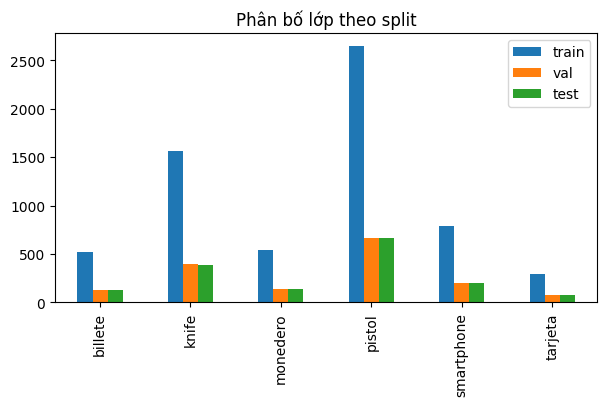

In [ ]:
#Nạp dữ liệu
(Xtr, ytr), (Xva, yva), (Xte, yte), names = load_hog(DATA_PATH)
K = len(names)
print("Lớp:", names)
print("Số mẫu train/val/test:", len(ytr), len(yva), len(yte), "| số đặc trưng:", Xtr.shape[1])

dist = pd.DataFrame({"train": np.bincount(ytr, minlength=K),
                     "val":   np.bincount(yva, minlength=K),
                     "test":  np.bincount(yte, minlength=K)}, index=names)
print(dist)
dist.plot(kind="bar", figsize=(7, 3.5), title="Phân bố lớp theo split"); plt.show()

fit 40s | n_iter=68/1000 | train F1=1.000 | val F1=0.591


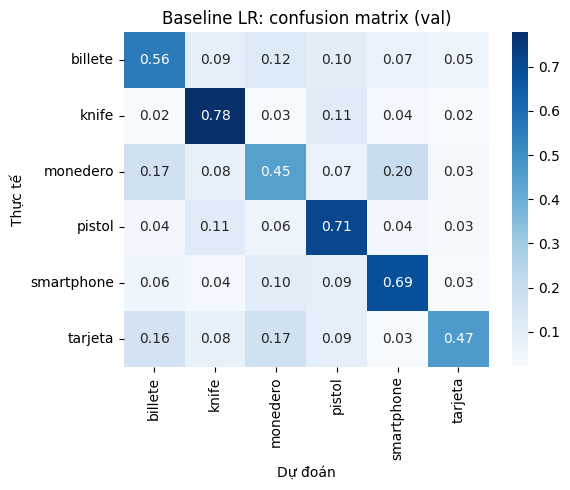

In [ ]:
#Baseline
t = time.time()
m_base = make_pipeline(StandardScaler(),
                       LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced"))
m_base.fit(Xtr, ytr)

r_tr = evaluate(m_base, Xtr, ytr, K)
r = register("Baseline LR (26k đặc trưng)", m_base, Feat(), {"train_macro_f1": r_tr["macro_f1"]})
n_it = m_base[-1].n_iter_.max()
print(f"fit {time.time()-t:.0f}s | n_iter={n_it}/1000 | "
      f"train F1={r_tr['macro_f1']:.3f} | val F1={r['macro_f1']:.3f}")
plot_cm(yva, m_base.predict(Xva), names, "Baseline LR: confusion matrix (val)")

In [ ]:
#Feature Selection
scaler = StandardScaler().fit(Xtr)
S_tr, S_va = scaler.transform(Xtr), scaler.transform(Xva)

C_FIXED = 1.0

#Phần 1: Select K Best: Filter
rows, fs_models = [], {}
for k in [1000, 3000, 8000]:
    t = time.time()
    sel = SelectKBest(f_classif, k=k).fit(S_tr, ytr)
    A, B = sel.transform(S_tr), sel.transform(S_va)
    m = LogisticRegression(C=C_FIXED, class_weight="balanced", max_iter=1000).fit(A, ytr)
    fs_models[k] = (m, sel)
    rows.append({"k_features": k,
                 "train_f1": f1_score(ytr, m.predict(A), average="macro"),
                 "val_f1":   f1_score(yva, m.predict(B), average="macro"),
                 "n_iter": int(m.n_iter_.max()),
                 "converged": bool(m.n_iter_.max() < m.max_iter),
                 "sec": round(time.time() - t)})
    print(rows[-1])
fs = pd.DataFrame(rows).sort_values("val_f1", ascending=False)
print(fs.round(4))

for k, (m, sel) in fs_models.items():
    r = fs[fs.k_features == k].iloc[0]
    register(f"SelectKBest({k}) + LR", m, Feat(scaler, sel), {"train_macro_f1": r.train_f1})

#Phần 2: Penalty L1: embedded
sel8k = fs_models[8000][1]
A8 = sel8k.transform(S_tr)

t = time.time()
m_l1 = LogisticRegression(penalty="l1", solver="saga", C=C_FIXED, class_weight="balanced",
                          max_iter=300, tol=1e-3).fit(A8, ytr)
nz = int((m_l1.coef_ != 0).sum())
print(f"L1: hệ số khác 0 = {nz}/{m_l1.coef_.size} | "
      f"converged={m_l1.n_iter_.max() < m_l1.max_iter} | {time.time()-t:.0f}s")
register("SelectKBest(8000) + LR L1", m_l1, Feat(scaler, sel8k),
         {"train_macro_f1": f1_score(ytr, m_l1.predict(A8), average="macro")})

{'k_features': 1000, 'train_f1': 0.8491012145822096, 'val_f1': 0.391875410832242, 'n_iter': 478, 'converged': True, 'sec': 26}
{'k_features': 3000, 'train_f1': 0.9998306990670495, 'val_f1': 0.4702039862319464, 'n_iter': 278, 'converged': True, 'sec': 40}
{'k_features': 8000, 'train_f1': 1.0, 'val_f1': 0.5412689529312908, 'n_iter': 87, 'converged': True, 'sec': 22}
   k_features  train_f1  val_f1  n_iter  converged  sec
2        8000    1.0000  0.5413      87       True   22
1        3000    0.9998  0.4702     278       True   40
0        1000    0.8491  0.3919     478       True   26


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


L1: hệ số khác 0 = 22563/48000 | converged=False | 1422s


{'experiment': 'SelectKBest(8000) + LR L1',
 'accuracy': 0.6398996235884568,
 'balanced_acc': np.float64(0.5636692299297341),
 'macro_f1': 0.5583633812021827,
 'weighted_f1': 0.642888788329917,
 'mcc': np.float64(0.5153002346160253),
 'log_loss': 1.5172250923836053,
 'train_macro_f1': 0.9999153385004768}

                    experiment  accuracy  balanced_acc  macro_f1  weighted_f1  \
0  Baseline LR (26k đặc trưng)    0.6782        0.6087    0.5914       0.6844   
4    SelectKBest(8000) + LR L1    0.6399        0.5637    0.5584       0.6429   
3       SelectKBest(8000) + LR    0.6242        0.5484    0.5413       0.6277   
2       SelectKBest(3000) + LR    0.5596        0.4727    0.4702       0.5609   
1       SelectKBest(1000) + LR    0.4900        0.4049    0.3919       0.5063   

      mcc  log_loss  train_macro_f1  
0  0.5746    2.1039          1.0000  
4  0.5153    1.5172          0.9999  
3  0.4944    2.8972          1.0000  
2  0.4027    3.2207          0.9998  
1  0.3338    2.5716          0.8491  

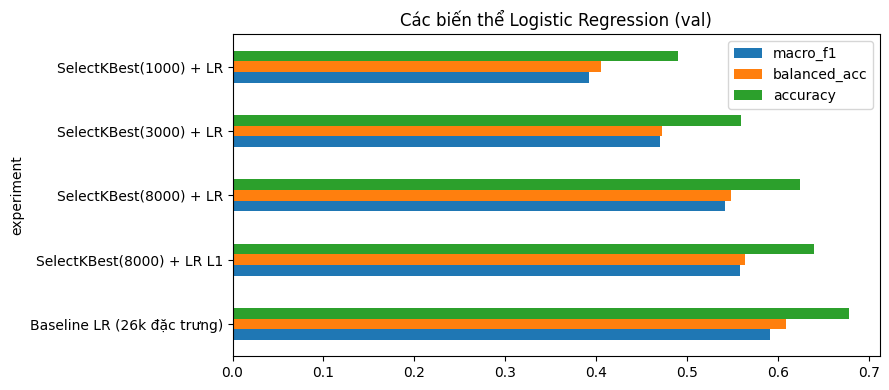

                    experiment  train_macro_f1  macro_f1  overfit_gap
0  Baseline LR (26k đặc trưng)          1.0000    0.5914       0.4086
4    SelectKBest(8000) + LR L1          0.9999    0.5584       0.4416
3       SelectKBest(8000) + LR          1.0000    0.5413       0.4587
2       SelectKBest(3000) + LR          0.9998    0.4702       0.5296
1       SelectKBest(1000) + LR          0.8491    0.3919       0.4572

In [ ]:
summary = pd.DataFrame(results).sort_values("macro_f1", ascending=False)
display(summary.round(4))
summary.set_index("experiment")[["macro_f1", "balanced_acc", "accuracy"]].plot(
    kind="barh", figsize=(9, 4), title="Các biến thể Logistic Regression (val)")
plt.tight_layout(); plt.show()

summary["overfit_gap"] = summary["train_macro_f1"] - summary["macro_f1"]
display(summary[["experiment", "train_macro_f1", "macro_f1", "overfit_gap"]].round(4))

Mô hình được chọn: Baseline LR (26k đặc trưng)
{'accuracy': 0.6776, 'balanced_acc': np.float64(0.5857), 'macro_f1': 0.5767, 'weighted_f1': 0.6818, 'mcc': np.float64(0.5686), 'log_loss': 2.1728, 'roc_auc_ovr_macro': np.float64(0.8752)}
              precision    recall  f1-score   support

     billete      0.439     0.504     0.469       129
       knife      0.713     0.762     0.737       391
    monedero      0.400     0.459     0.428       135
      pistol      0.825     0.739     0.779       662
  smartphone      0.665     0.685     0.675       197
     tarjeta      0.380     0.365     0.372        74

    accuracy                          0.678      1588
   macro avg      0.570     0.586     0.577      1588
weighted avg      0.689     0.678     0.682      1588



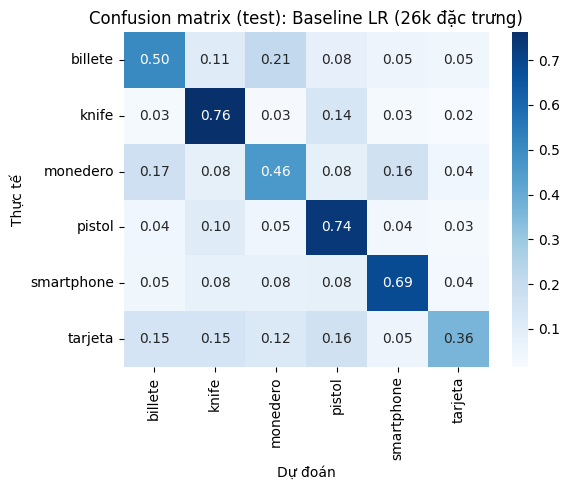

pistol -> knife: 69 ảnh
knife -> pistol: 55 ảnh
pistol -> monedero: 32 ảnh
pistol -> billete: 29 ảnh
billete -> monedero: 27 ảnh


In [ ]:
#Train
best_name = summary.iloc[0]["experiment"]
final_model, final_feat = candidates[best_name]
print("Mô hình được chọn:", best_name)

Fte = final_feat(Xte)
pred, proba = final_model.predict(Fte), final_model.predict_proba(Fte)

test_metrics = evaluate(final_model, Fte, yte, K)
test_metrics["roc_auc_ovr_macro"] = roc_auc_score(yte, proba, multi_class="ovr", average="macro")
print({k: round(v, 4) for k, v in test_metrics.items()})
print(classification_report(yte, pred, target_names=names, digits=3))
plot_cm(yte, pred, names, f"Confusion matrix (test): {best_name}")

#Cặp lớp nhầm lẫn nhiều nhất
cm = confusion_matrix(yte, pred); np.fill_diagonal(cm, 0)
for n, a, b_ in sorted([(cm[i, j], names[i], names[j])
                        for i in range(K) for j in range(K) if cm[i, j]], reverse=True)[:5]:
    print(f"{a} -> {b_}: {n} ảnh")

In [ ]:
#Output
os.makedirs(OUT, exist_ok=True)

def dump(X, y, name):
    F = final_feat(X)
    df = pd.DataFrame(final_model.predict_proba(F), columns=[f"p_{c}" for c in names])
    df.insert(0, "y_true", [names[i] for i in y])
    df.insert(1, "y_pred", [names[i] for i in final_model.predict(F)])
    df.to_csv(f"{OUT}/lr_{name}_predictions.csv", index=False)
dump(Xva, yva, "val"); dump(Xte, yte, "test")

json.dump({"model": best_name, "test_metrics": test_metrics},
          open(f"{OUT}/lr_test_metrics.json", "w"), indent=2, ensure_ascii=False)
summary.to_csv(f"{OUT}/lr_val_experiments.csv", index=False)
fs.to_csv(f"{OUT}/lr_feature_selection.csv", index=False)
joblib.dump({"model": final_model, "feat": final_feat, "class_names": names},
            f"{OUT}/lr_final.joblib")
print("Đã lưu vào", OUT)